<a href="https://colab.research.google.com/github/Merdgn/BankInsight-AI/blob/main/notebooks/01_data_understanding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# BankInsight AI — Data Understanding

## Objective
Explore the UCI Bank Marketing dataset and understand its structure before developing machine learning models.

**Prediction target:** Term deposit subscription (`y`)

**Dataset:** UCI Bank Marketing (`bank-full.csv`)

**Important:** The `duration` feature will be excluded from pre-call predictive modeling to prevent target-related information leakage.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import requests
import io
import zipfile

pd.set_option("display.max_columns", None)

print("BankInsight AI environment is ready!")


BankInsight AI environment is ready!


In [2]:

# Official UCI Bank Marketing dataset
DATA_URL = (
    "https://archive.ics.uci.edu/static/public/222/"
    "bank+marketing.zip"
)

response = requests.get(DATA_URL, timeout=60)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as outer_zip:
    bank_archive = next(
        name for name in outer_zip.namelist()
        if name.endswith("bank.zip")
    )
    bank_bytes = outer_zip.read(bank_archive)

with zipfile.ZipFile(io.BytesIO(bank_bytes)) as inner_zip:
    csv_filename = next(
        name for name in inner_zip.namelist()
        if name.endswith("bank-full.csv")
    )
    with inner_zip.open(csv_filename) as csv_file:
        df = pd.read_csv(csv_file, sep=";")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nTarget distribution:")
print(df["y"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)


Rows: 45211
Columns: 17

Column names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Target distribution:
y
no     39922
yes     5289
Name: count, dtype: int64

Missing values:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Data types:
age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object



## 3. Exploratory Data Analysis (EDA)

### 3.1 Target Variable Distribution

This analysis examines the distribution of term deposit subscriptions to identify potential class imbalance and establish a baseline for model evaluation.


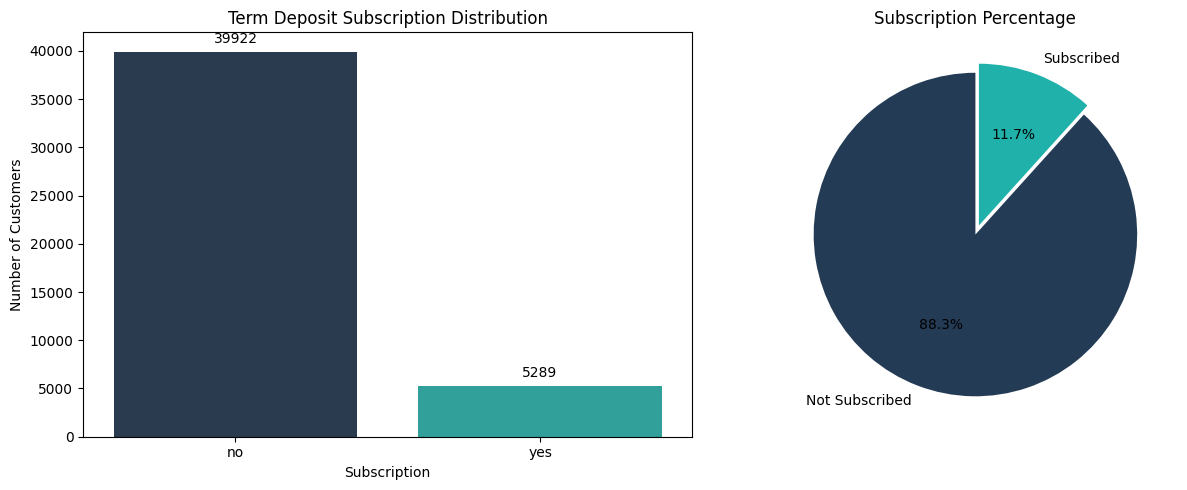

Class Distribution:
y
no     39922
yes     5289
Name: count, dtype: int64

Class Percentages:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64

Majority Class Baseline Accuracy: 0.8830


In [4]:

# 3.1 Target Variable Distribution

target_counts = df["y"].value_counts()
target_percentages = df["y"].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

colors = ["#243B55", "#20B2AA"]

# Count plot
sns.countplot(
    data=df,
    x="y",
    order=["no", "yes"],
    hue="y",
    hue_order=["no", "yes"],
    palette=colors,
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Term Deposit Subscription Distribution")
axes[0].set_xlabel("Subscription")
axes[0].set_ylabel("Number of Customers")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%d", padding=4)

# Percentage pie chart
axes[1].pie(
    [target_counts["no"], target_counts["yes"]],
    labels=["Not Subscribed", "Subscribed"],
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    explode=(0, 0.06)
)

axes[1].set_title("Subscription Percentage")

plt.tight_layout()
plt.show()

print("Class Distribution:")
print(target_counts)

print("\nClass Percentages:")
print(target_percentages.round(2))

majority_baseline = target_counts.max() / len(df)

print(f"\nMajority Class Baseline Accuracy: {majority_baseline:.4f}")



### Findings — Target Distribution

The dataset contains 45,211 observations, of which 39,922
(88.3%) belong to the negative class and 5,289 (11.7%)
belong to the positive class.

This distribution indicates a substantial class imbalance.

A majority-class classifier that predicts "no" for every
customer would achieve approximately 88.3% accuracy
without identifying any actual subscribers.

Therefore, accuracy alone is insufficient for evaluating
the predictive performance of this project.

In addition to accuracy, precision, recall, F1-score,
ROC-AUC, PR-AUC and the confusion matrix will be used.

Class weighting and decision-threshold optimization may
also be evaluated during model development.



### 3.2 Customer Demographic Analysis

#### 3.2.1 Age Distribution and Subscription Rate

Objective: Analyze the age distribution of customers and
investigate how term deposit subscription rates vary
across different age groups.


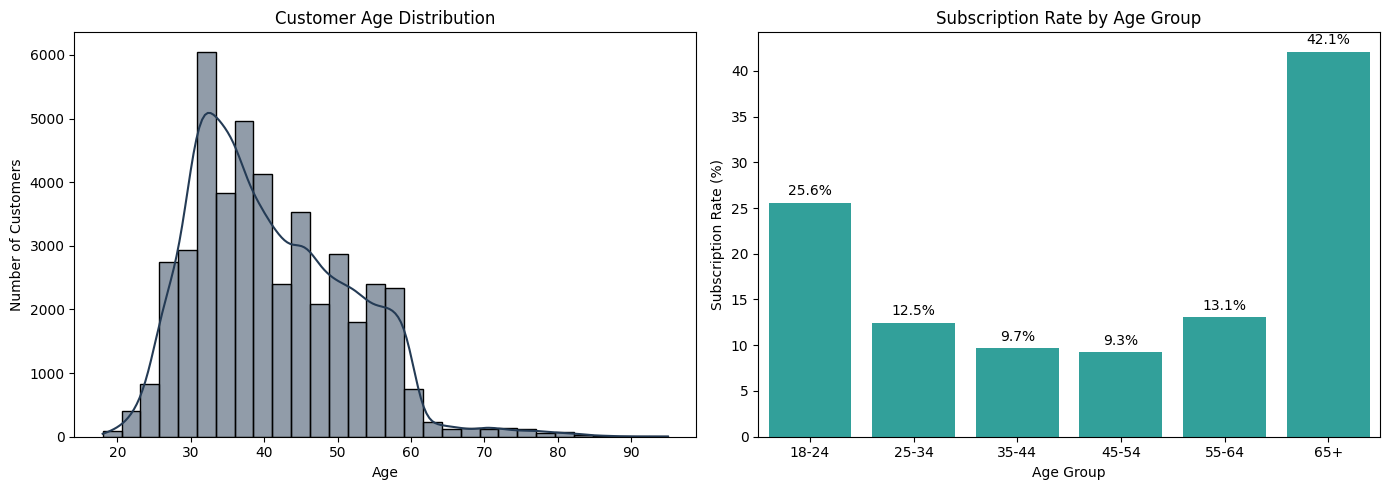

,age_group,customers,subscriptions,subscription_rate
0,18-24,809,207,25.587145
1,25-34,14204,1773,12.482399
2,35-44,14534,1404,9.660107
3,45-54,9958,923,9.268930
4,55-64,4896,641,13.092320
5,65+,810,341,42.098765



Age Summary Statistics:


,age
count,45211.000000
mean,40.936210
std,10.618762
min,18.000000
25%,33.000000
50%,39.000000
75%,48.000000
max,95.000000


In [5]:

# Age Distribution Analysis

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Overall age distribution
sns.histplot(
    data=df,
    x="age",
    bins=30,
    kde=True,
    color="#243B55",
    ax=axes[0]
)

axes[0].set_title("Customer Age Distribution")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Number of Customers")

# Subscription rate by age group
age_bins = [0, 25, 35, 45, 55, 65, np.inf]
age_labels = ["18-24", "25-34", "35-44", "45-54", "55-64", "65+"]

age_analysis = df.copy()

age_analysis["age_group"] = pd.cut(
    age_analysis["age"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

age_summary = (
    age_analysis.groupby("age_group", observed=True)["y"]
    .agg(
        customers="count",
        subscriptions=lambda x: (x == "yes").sum(),
        subscription_rate=lambda x: (x == "yes").mean() * 100
    )
    .reset_index()
)

sns.barplot(
    data=age_summary,
    x="age_group",
    y="subscription_rate",
    color="#20B2AA",
    ax=axes[1]
)

axes[1].set_title("Subscription Rate by Age Group")
axes[1].set_xlabel("Age Group")
axes[1].set_ylabel("Subscription Rate (%)")

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

display(age_summary)

print("\nAge Summary Statistics:")
display(df["age"].describe())



### Findings — Age Distribution and Subscription Behavior

The age distribution is concentrated among middle-aged
customers, with a mean age of 40.94 years and a median
of 39 years. Customer ages range from 18 to 95.

Subscription rates vary considerably across age groups.

Customers aged 65 and above have the highest subscription
rate (42.1%), followed by customers aged 18–24 (25.6%).

In contrast, the 35–44 and 45–54 age groups have lower
subscription rates of approximately 9.7% and 9.3%.

This pattern suggests a potentially nonlinear relationship
between customer age and term deposit subscription.

However, the youngest and oldest groups contain fewer
observations, and the observed associations should not
be interpreted as causal effects.

Age-related feature engineering may be evaluated during
model development, while retaining the original age
variable for comparison.

Older customers will not be removed solely because of
their age, as these observations may represent valid
customer profiles.



#### 3.2.2 Job Distribution and Subscription Analysis

**Objective:** Examine the distribution of customer occupations
and investigate differences in term deposit subscription rates
across occupational groups.

This analysis considers both customer counts and subscription
rates to avoid misleading conclusions from small groups.


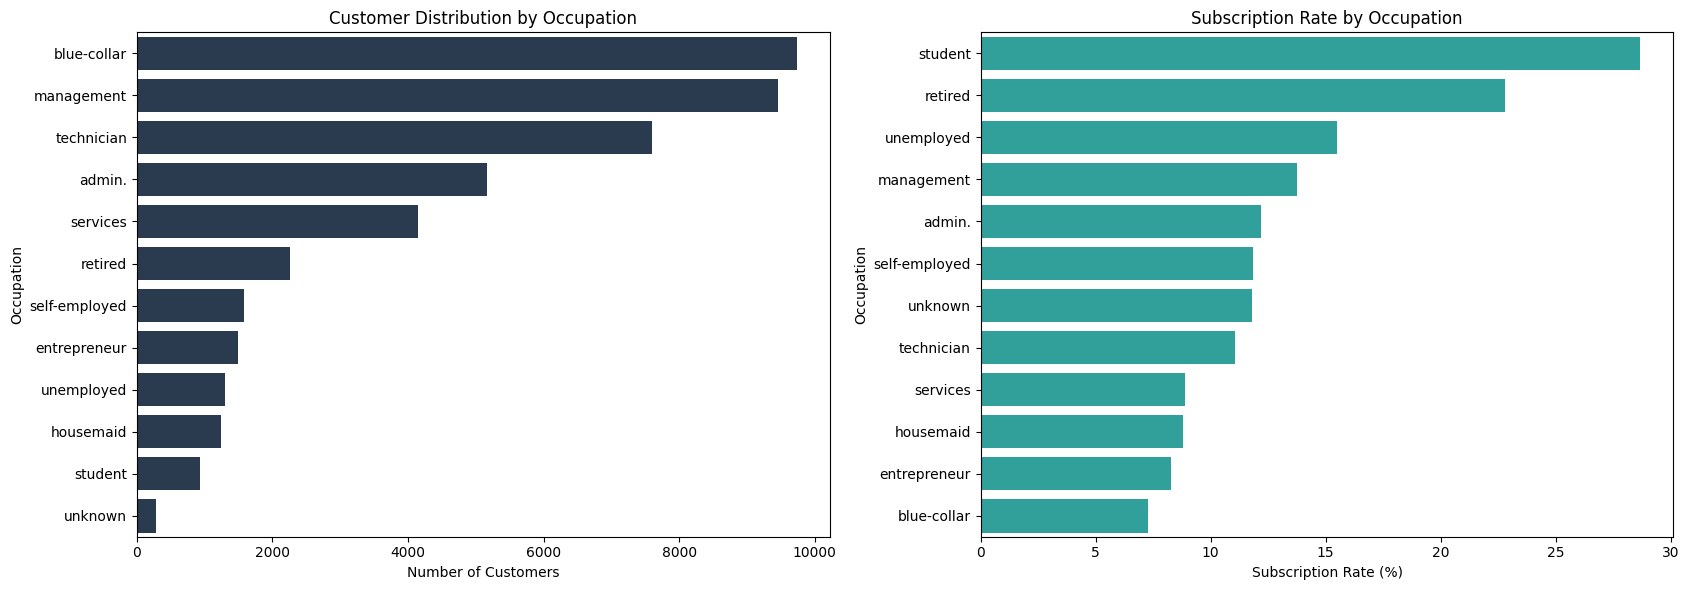

Job Distribution and Subscription Rates:


,job,customers,subscriptions,subscription_rate
8,student,938,269,28.68
5,retired,2264,516,22.79
10,unemployed,1303,202,15.50
4,management,9458,1301,13.76
0,admin.,5171,631,12.20
6,self-employed,1579,187,11.84
11,unknown,288,34,11.81
9,technician,7597,840,11.06
7,services,4154,369,8.88
3,housemaid,1240,109,8.79



Unknown job records: 288
Unknown job percentage: 0.64%


In [6]:

# 3.2.2 Job Distribution and Subscription Analysis

job_summary = (
    df.groupby("job")["y"]
    .agg(
        customers="count",
        subscriptions=lambda x: (x == "yes").sum(),
        subscription_rate=lambda x: (x == "yes").mean() * 100
    )
    .reset_index()
)

job_summary = job_summary.sort_values(
    by="customers",
    ascending=False
)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# 1. Customer distribution by job
sns.barplot(
    data=job_summary,
    x="customers",
    y="job",
    color="#243B55",
    ax=axes[0]
)

axes[0].set_title("Customer Distribution by Occupation")
axes[0].set_xlabel("Number of Customers")
axes[0].set_ylabel("Occupation")

# 2. Subscription rate by job
job_rate_sorted = job_summary.sort_values(
    by="subscription_rate",
    ascending=False
)

sns.barplot(
    data=job_rate_sorted,
    x="subscription_rate",
    y="job",
    color="#20B2AA",
    ax=axes[1]
)

axes[1].set_title("Subscription Rate by Occupation")
axes[1].set_xlabel("Subscription Rate (%)")
axes[1].set_ylabel("Occupation")

plt.tight_layout()
plt.show()

# Detailed summary
print("Job Distribution and Subscription Rates:")
display(
    job_summary.sort_values(
        by="subscription_rate",
        ascending=False
    ).round(2)
)

# Unknown job values
unknown_count = (df["job"] == "unknown").sum()
unknown_percentage = unknown_count / len(df) * 100

print(f"\nUnknown job records: {unknown_count}")
print(f"Unknown job percentage: {unknown_percentage:.2f}%")



### Findings — Occupation and Subscription Behavior

The occupation analysis reveals substantial differences
in term deposit subscription rates across job categories.

Students have the highest subscription rate (28.68%),
followed by retired customers (22.79%) and unemployed
customers (15.50%).

Although blue-collar workers represent the largest
occupational group with 9,732 observations, their
subscription rate is relatively low (7.27%).

In contrast, the management group accounts for the
highest absolute number of subscriptions (1,301),
with a subscription rate of 13.76%.

These findings demonstrate the importance of distinguishing
between subscription rates and absolute subscription counts.

The dataset also contains 288 records (0.64%) with
unknown occupation values. These observations will be
retained during exploratory analysis and reviewed during
data preprocessing.

The observed association between occupation and
subscription may be influenced by age, financial
characteristics, and campaign-related factors.

Therefore, these descriptive results should not be
interpreted as evidence of a causal relationship.



#### 3.2.3 Education Level and Subscription Analysis

**Objective:** Analyze the distribution of customers
across education levels and investigate the relationship
between educational attainment and term deposit
subscription rates.

The analysis will also identify unknown education
records and examine their potential implications
for data preprocessing.


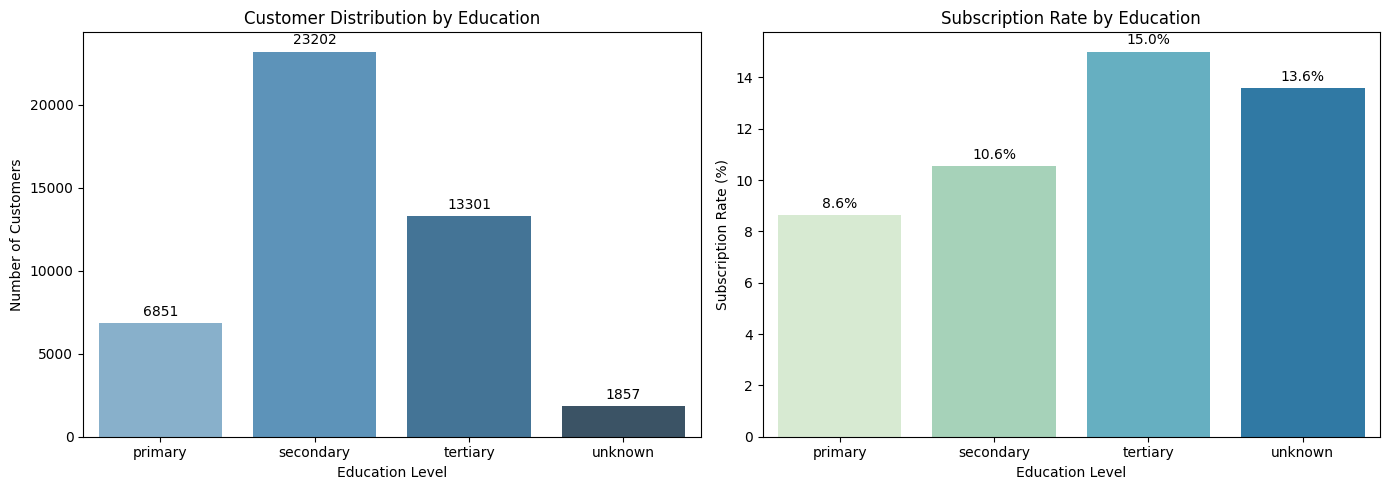

Education Distribution and Subscription Rates:


,education,customers,subscriptions,subscription_rate
0,primary,6851,591,8.63
1,secondary,23202,2450,10.56
2,tertiary,13301,1996,15.01
3,unknown,1857,252,13.57



Unknown education records: 1857
Unknown education percentage: 4.11%

Unique education values:
['tertiary' 'secondary' 'unknown' 'primary']


In [7]:

# 3.2.3 Education Level and Subscription Analysis

education_order = [
    "primary",
    "secondary",
    "tertiary",
    "unknown"
]

# Education-level summary
education_summary = (
    df.groupby("education")["y"]
    .agg(
        customers="count",
        subscriptions=lambda x: (x == "yes").sum(),
        subscription_rate=lambda x: (x == "yes").mean() * 100
    )
    .reindex(education_order)
    .reset_index()
)

# Create visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Number of customers by education level
sns.barplot(
    data=education_summary,
    x="education",
    y="customers",
    hue="education",
    palette="Blues_d",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Customer Distribution by Education")
axes[0].set_xlabel("Education Level")
axes[0].set_ylabel("Number of Customers")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f", padding=3)

# 2. Subscription rate by education level
sns.barplot(
    data=education_summary,
    x="education",
    y="subscription_rate",
    hue="education",
    palette="GnBu",
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Subscription Rate by Education")
axes[1].set_xlabel("Education Level")
axes[1].set_ylabel("Subscription Rate (%)")

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

# Display detailed statistics
print("Education Distribution and Subscription Rates:")
display(education_summary.round(2))

# Unknown education records
unknown_education = (df["education"] == "unknown").sum()
unknown_percentage = unknown_education / len(df) * 100

print(f"\nUnknown education records: {unknown_education}")
print(f"Unknown education percentage: {unknown_percentage:.2f}%")

# Check possible unexpected categories
print("\nUnique education values:")
print(df["education"].unique())



### Findings — Education Level and Subscription Behavior

The education analysis indicates a positive association
between educational attainment and term deposit
subscription rates among customers with known education
levels.

Customers with tertiary education have the highest
subscription rate (15.01%), followed by secondary
education (10.56%) and primary education (8.63%).

Although secondary education represents the largest
customer group with 23,202 observations, tertiary-educated
customers demonstrate the highest subscription rate
among the known education categories.

The dataset contains 1,857 observations (4.11%) with
unknown education levels. This group has a subscription
rate of 13.57%, suggesting that removing these records
without further analysis could lead to information loss.

Therefore, unknown education values will initially be
preserved as a separate category during preprocessing.

Education will be considered as a potential predictive
feature, with suitable encoding strategies evaluated
during model development.

These descriptive associations do not establish causality,
and their relationship with other demographic and
financial variables requires further investigation.



#### 3.2.4 Marital Status and Subscription Analysis

**Objective:** Analyze the distribution of customers
across marital status categories and evaluate the
association between marital status and term deposit
subscription behavior.

The analysis compares customer counts, subscription
counts, and subscription rates while checking
for missing or unexpected category values.


Unique marital status values:
marital
married     27214
single      12790
divorced     5207
Name: count, dtype: int64


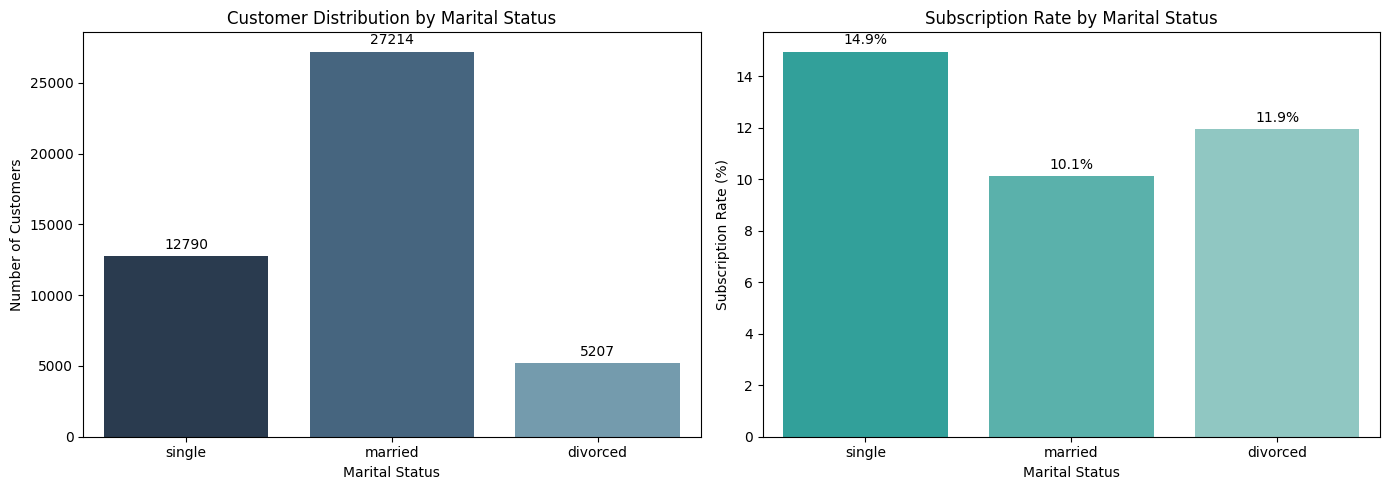


Marital Status Summary:


,marital,customers,subscriptions,subscription_rate
0,single,12790,1912,14.95
1,married,27214,2755,10.12
2,divorced,5207,622,11.95



Missing values: 0
Unexpected categories: set()


In [8]:

# 3.2.4 Marital Status and Subscription Analysis

marital_order = ["single", "married", "divorced"]

# Check observed categories
print("Unique marital status values:")
print(df["marital"].value_counts(dropna=False))

# Calculate customer counts and subscription rates
marital_summary = (
    df.groupby("marital")["y"]
    .agg(
        customers="count",
        subscriptions=lambda x: (x == "yes").sum(),
        subscription_rate=lambda x: (x == "yes").mean() * 100
    )
    .reindex(marital_order)
    .reset_index()
)

# Create two visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=marital_summary,
    x="marital",
    y="customers",
    hue="marital",
    palette=["#243B55", "#3D6688", "#6B9FB6"],
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Customer Distribution by Marital Status")
axes[0].set_xlabel("Marital Status")
axes[0].set_ylabel("Number of Customers")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f", padding=3)

sns.barplot(
    data=marital_summary,
    x="marital",
    y="subscription_rate",
    hue="marital",
    palette=["#20B2AA", "#4BBFB8", "#87D0CA"],
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Subscription Rate by Marital Status")
axes[1].set_xlabel("Marital Status")
axes[1].set_ylabel("Subscription Rate (%)")

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

print("\nMarital Status Summary:")
display(marital_summary.round(2))

# Data quality checks
expected_categories = set(marital_order)
observed_categories = set(df["marital"].dropna().unique())

unexpected = observed_categories - expected_categories

print("\nMissing values:", df["marital"].isna().sum())
print("Unexpected categories:", unexpected)



### Findings — Marital Status and Subscription Behavior

The marital status analysis reveals differences in term
deposit subscription rates across customer groups.

Single customers have the highest subscription rate
(14.95%), followed by divorced or widowed customers
(11.95%) and married customers (10.12%).

Although married customers represent the largest group
with 27,214 observations, their subscription rate is
lower than that of single customers.

Nevertheless, married customers account for the highest
absolute number of subscriptions (2,755), demonstrating
the distinction between subscription volume and
subscription rate.

No missing values or unexpected categories were
identified in the marital status variable.

The observed differences may be associated with
other demographic characteristics, particularly age
and occupation. Therefore, these findings should
not be interpreted as causal relationships.

The predictive contribution and potential fairness
implications of marital status will be assessed
during model development.



### 3.3 Financial Features Analysis

#### 3.3.1 Bank Balance Distribution and Subscription Analysis

**Objective:** Examine the distribution of customer bank
balances, identify potentially unusual values, and analyze
the relationship between account balance and term deposit
subscription rates.

Negative and extreme balances will be investigated rather
than automatically removed.


Balance Summary Statistics:


,balance
count,45211.000000
mean,1362.272058
std,3044.765829
min,-8019.000000
25%,72.000000
50%,448.000000
75%,1428.000000
max,102127.000000



Negative balance records: 3766
Zero balance records: 3514

IQR Lower Bound: -1962.0
IQR Upper Bound: 3462.0
Potential Outliers: 4729
Outlier Percentage: 10.46 %


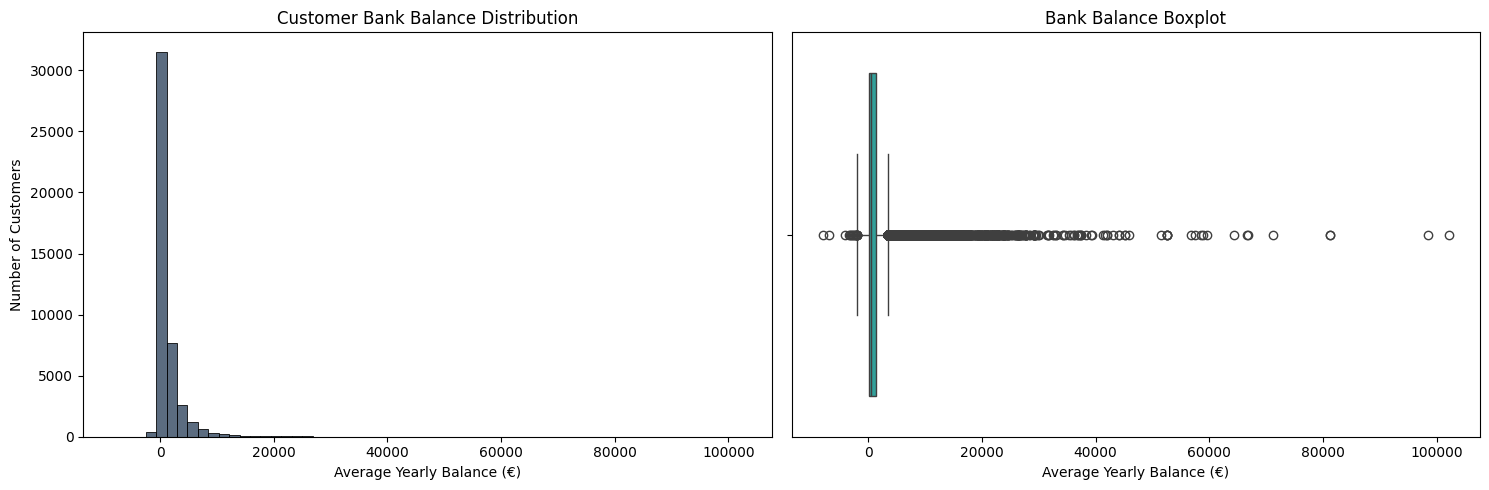

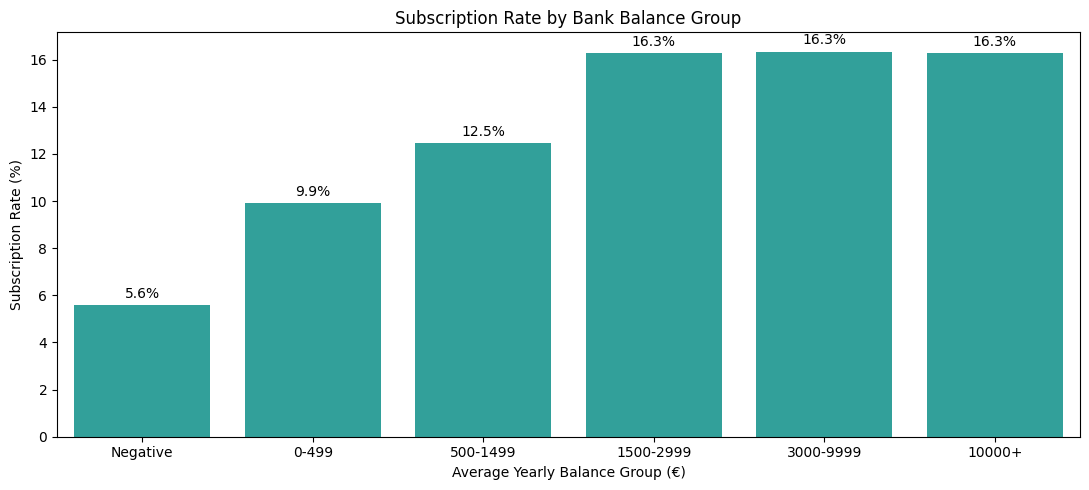


Balance Group Summary:


,balance_group,customers,subscriptions,subscription_rate
0,Negative,3766,210,5.58
1,0-499,19871,1972,9.92
2,500-1499,10673,1329,12.45
3,1500-2999,5286,861,16.29
4,3000-9999,4786,782,16.34
5,10000+,829,135,16.28


In [9]:

# 3.3.1 Bank Balance Distribution and Subscription Analysis

# 1. Descriptive statistics
print("Balance Summary Statistics:")
display(df["balance"].describe())

print("\nNegative balance records:",
      (df["balance"] < 0).sum())

print("Zero balance records:",
      (df["balance"] == 0).sum())

# 2. IQR-based outlier detection
Q1 = df["balance"].quantile(0.25)
Q3 = df["balance"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (df["balance"] < lower_bound) |
    (df["balance"] > upper_bound)
)

print("\nIQR Lower Bound:", round(lower_bound, 2))
print("IQR Upper Bound:", round(upper_bound, 2))
print("Potential Outliers:", outlier_mask.sum())
print("Outlier Percentage:",
      round(outlier_mask.mean() * 100, 2), "%")

# 3. Distribution visualizations
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    df["balance"],
    bins=60,
    color="#243B55",
    ax=axes[0]
)

axes[0].set_title("Customer Bank Balance Distribution")
axes[0].set_xlabel("Average Yearly Balance (€)")
axes[0].set_ylabel("Number of Customers")

sns.boxplot(
    x=df["balance"],
    color="#20B2AA",
    ax=axes[1]
)

axes[1].set_title("Bank Balance Boxplot")
axes[1].set_xlabel("Average Yearly Balance (€)")

plt.tight_layout()
plt.show()

# 4. Balance groups and subscription rates
# Exploratory bins defined before model development
balance_bins = [
    -np.inf, 0, 500, 1500, 3000, 10000, np.inf
]

balance_labels = [
    "Negative",
    "0-499",
    "500-1499",
    "1500-2999",
    "3000-9999",
    "10000+"
]

balance_analysis = df.copy()

balance_analysis["balance_group"] = pd.cut(
    balance_analysis["balance"],
    bins=balance_bins,
    labels=balance_labels,
    right=False
)

balance_summary = (
    balance_analysis.groupby("balance_group", observed=True)["y"]
    .agg(
        customers="count",
        subscriptions=lambda x: (x == "yes").sum(),
        subscription_rate=lambda x: (x == "yes").mean() * 100
    )
    .reset_index()
)

plt.figure(figsize=(11, 5))

ax = sns.barplot(
    data=balance_summary,
    x="balance_group",
    y="subscription_rate",
    color="#20B2AA"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.title("Subscription Rate by Bank Balance Group")
plt.xlabel("Average Yearly Balance Group (€)")
plt.ylabel("Subscription Rate (%)")
plt.tight_layout()
plt.show()

print("\nBalance Group Summary:")
display(balance_summary.round(2))



### Findings — Bank Balance Distribution and Subscription Behavior

The balance variable exhibits a strongly right-skewed
distribution, with a mean of €1,362.27 and a median
of €448.

Customer balances range from -€8,019 to €102,127,
indicating substantial variability.

A total of 3,766 customers have negative balances,
while 3,514 customers have zero balances.

Using the 1.5 × IQR rule, 4,729 observations (10.46%)
were flagged as potential outliers.

These observations will not be automatically removed,
as extreme balances may represent valid financial
characteristics rather than data errors.

Subscription rates generally increase across the
lower balance groups, from 5.58% for customers with
negative balances to approximately 16.3% for customers
with balances above €1,500.

However, subscription rates remain relatively stable
across the higher balance groups, suggesting a
potentially nonlinear relationship.

During model development, appropriate scaling and
transformation strategies will be evaluated.

All preprocessing parameters will be learned using
training data only to prevent data leakage.

These findings describe associations and do not
establish a causal effect of balance on subscription.



#### 3.3.2 Housing Loan and Subscription Analysis

**Objective:** Investigate the relationship between
housing loan status and term deposit subscription.

This analysis examines the distribution of customers
with and without housing loans, compares subscription
rates, and checks for missing or unexpected values.

The results will be used to assess the potential
predictive relevance of the housing variable.


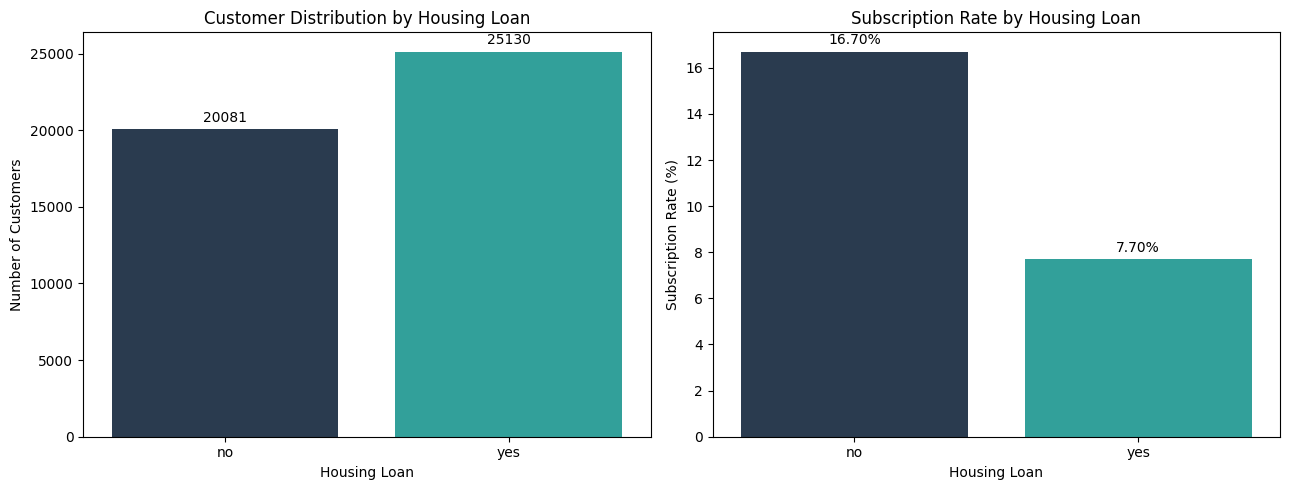

Housing Loan Summary:


,housing,customers,subscriptions,subscription_rate,customer_percentage
0,no,20081,3354,16.7,44.42
1,yes,25130,1935,7.7,55.58



Subscription rate difference (No - Yes): 9.00 percentage points

Missing values: 0
Unexpected categories: set()


In [10]:

# 3.3.2 Housing Loan and Subscription Analysis

housing_order = ["no", "yes"]

# 1. Summary statistics
housing_summary = (
    df.groupby("housing")["y"]
    .agg(
        customers="count",
        subscriptions=lambda x: (x == "yes").sum(),
        subscription_rate=lambda x: (x == "yes").mean() * 100
    )
    .reindex(housing_order)
    .reset_index()
)

housing_summary["customer_percentage"] = (
    housing_summary["customers"] / len(df) * 100
)

# 2. Visualizations
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

colors = ["#243B55", "#20B2AA"]

sns.barplot(
    data=housing_summary,
    x="housing",
    y="customers",
    hue="housing",
    palette=colors,
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Customer Distribution by Housing Loan")
axes[0].set_xlabel("Housing Loan")
axes[0].set_ylabel("Number of Customers")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f", padding=3)

sns.barplot(
    data=housing_summary,
    x="housing",
    y="subscription_rate",
    hue="housing",
    palette=colors,
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Subscription Rate by Housing Loan")
axes[1].set_xlabel("Housing Loan")
axes[1].set_ylabel("Subscription Rate (%)")

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

# 3. Detailed summary
print("Housing Loan Summary:")
display(housing_summary.round(2))

# 4. Difference in subscription rates
rate_no = housing_summary.loc[
    housing_summary["housing"] == "no",
    "subscription_rate"
].iloc[0]

rate_yes = housing_summary.loc[
    housing_summary["housing"] == "yes",
    "subscription_rate"
].iloc[0]

print(
    f"\nSubscription rate difference (No - Yes): "
    f"{rate_no - rate_yes:.2f} percentage points"
)

# 5. Data quality checks
print("\nMissing values:", df["housing"].isna().sum())

unexpected = set(df["housing"].dropna().unique()) - {"yes", "no"}
print("Unexpected categories:", unexpected)



### Findings — Housing Loan and Subscription Behavior

The housing loan analysis reveals a substantial difference
in term deposit subscription rates between customers
with and without housing loans.

Customers without housing loans have a subscription rate
of 16.70%, compared with 7.70% among customers who
have housing loans.

This represents a difference of 9.00 percentage points.

Although customers with housing loans account for
55.58% of the dataset, they demonstrate a considerably
lower subscription rate.

The subscription rate among customers without housing
loans is approximately 2.17 times that of customers
with housing loans.

No missing values or unexpected categories were
identified in the housing variable.

These findings suggest that housing loan status may
provide useful predictive information.

However, the observed association does not establish
causality. Other customer characteristics, including
age, account balance, occupation, and campaign
conditions, may contribute to the differences.

The predictive contribution of this feature will
be evaluated during model development.



#### 3.3.3 Personal Loan and Subscription Analysis

**Objective:** Investigate the association between
personal loan status and term deposit subscriptions.

This analysis compares customer distribution,
subscription counts, and subscription rates across
personal loan categories.

The analysis also examines data quality and the
potential predictive relevance of the loan variable.


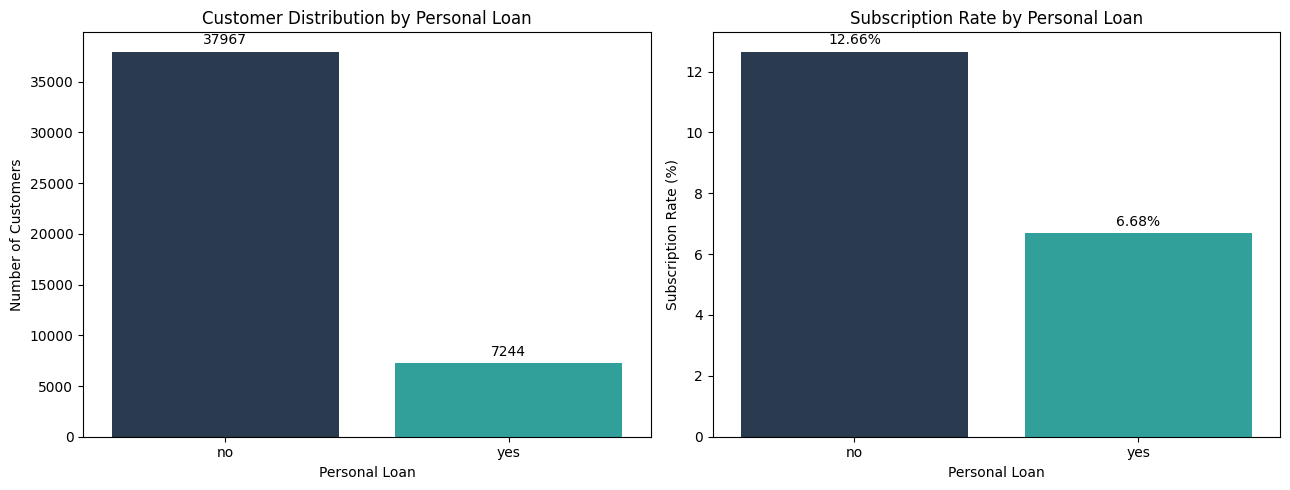

Personal Loan Summary:


,loan,customers,subscriptions,subscription_rate,customer_percentage
0,no,37967,4805,12.66,83.98
1,yes,7244,484,6.68,16.02



Subscription rate difference (No - Yes): 5.97 percentage points

Missing values: 0
Unexpected categories: set()


In [11]:

# 3.3.3 Personal Loan and Subscription Analysis

loan_order = ["no", "yes"]

# 1. Summary statistics
loan_summary = (
    df.groupby("loan")["y"]
    .agg(
        customers="count",
        subscriptions=lambda x: (x == "yes").sum(),
        subscription_rate=lambda x: (x == "yes").mean() * 100
    )
    .reindex(loan_order)
    .reset_index()
)

loan_summary["customer_percentage"] = (
    loan_summary["customers"] / len(df) * 100
)

# 2. Visualizations
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

colors = ["#243B55", "#20B2AA"]

sns.barplot(
    data=loan_summary,
    x="loan",
    y="customers",
    hue="loan",
    palette=colors,
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Customer Distribution by Personal Loan")
axes[0].set_xlabel("Personal Loan")
axes[0].set_ylabel("Number of Customers")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f", padding=3)

sns.barplot(
    data=loan_summary,
    x="loan",
    y="subscription_rate",
    hue="loan",
    palette=colors,
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Subscription Rate by Personal Loan")
axes[1].set_xlabel("Personal Loan")
axes[1].set_ylabel("Subscription Rate (%)")

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

# 3. Detailed summary
print("Personal Loan Summary:")
display(loan_summary.round(2))

# 4. Subscription rate difference
rate_no = loan_summary.loc[
    loan_summary["loan"] == "no",
    "subscription_rate"
].iloc[0]

rate_yes = loan_summary.loc[
    loan_summary["loan"] == "yes",
    "subscription_rate"
].iloc[0]

print(
    f"\nSubscription rate difference (No - Yes): "
    f"{rate_no - rate_yes:.2f} percentage points"
)

# 5. Data quality checks
print("\nMissing values:", df["loan"].isna().sum())

unexpected = (
    set(df["loan"].dropna().unique()) - {"yes", "no"}
)

print("Unexpected categories:", unexpected)



### Findings — Personal Loan and Subscription Behavior

The personal loan analysis reveals a notable association
between personal loan status and term deposit subscription.

Customers without personal loans account for 83.98%
of the dataset and demonstrate a subscription rate
of 12.66%.

In contrast, customers with personal loans represent
16.02% of the observations and have a substantially
lower subscription rate of 6.68%.

The difference between these groups is approximately
5.97 percentage points.

Customers without personal loans have approximately
1.90 times the subscription rate of customers with
personal loans.

This pattern is consistent with the housing loan
analysis, where customers without housing loans
also demonstrated higher subscription rates.

However, these descriptive findings do not establish
a causal relationship between credit obligations
and subscription decisions.

No missing values or unexpected categories were
identified in the personal loan variable.

During feature engineering, combined housing and
personal loan indicators may be evaluated to determine
whether they improve predictive performance.

The contribution of these features will be assessed
using appropriate validation procedures.



#### 3.3.4 Credit Default and Subscription Analysis

**Objective:** Investigate the relationship between
credit default status and term deposit subscription.

This analysis compares customer counts and subscription
rates across default categories, examines class imbalance,
and identifies potential data quality issues.

Special attention will be given to categories with
small sample sizes and the reliability of their
observed subscription rates.


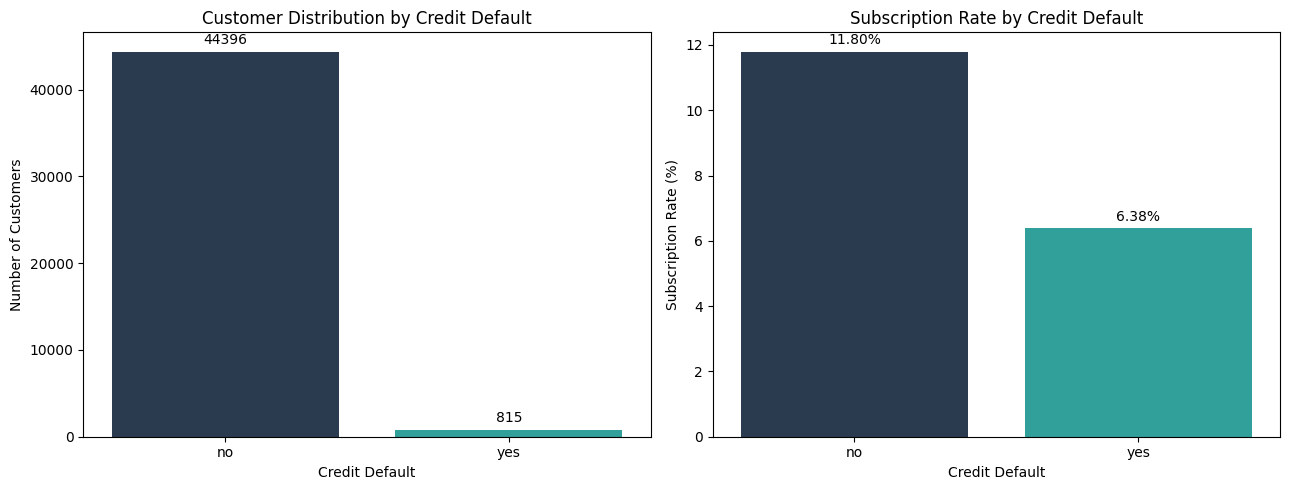

Credit Default Summary:


,default,customers,subscriptions,subscription_rate,customer_percentage
0,no,44396,5237,11.80,98.2
1,yes,815,52,6.38,1.8



Subscription Rate Difference (No - Yes): 5.42 percentage points

Missing values: 0
Unexpected categories: set()

Credit Default Category Counts:
default
no     44396
yes      815
Name: count, dtype: int64

Subscriptions by Credit Default:
y           no   yes
default             
no       39159  5237
yes        763    52


In [12]:

# 3.3.4 Credit Default and Subscription Analysis

default_order = ["no", "yes"]

# 1. Summary statistics
default_summary = (
    df.groupby("default")["y"]
    .agg(
        customers="count",
        subscriptions=lambda x: (x == "yes").sum(),
        subscription_rate=lambda x: (x == "yes").mean() * 100
    )
    .reindex(default_order)
    .reset_index()
)

default_summary["customer_percentage"] = (
    default_summary["customers"] / len(df) * 100
)

# 2. Visualizations
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

colors = ["#243B55", "#20B2AA"]

sns.barplot(
    data=default_summary,
    x="default",
    y="customers",
    hue="default",
    palette=colors,
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Customer Distribution by Credit Default")
axes[0].set_xlabel("Credit Default")
axes[0].set_ylabel("Number of Customers")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f", padding=3)

sns.barplot(
    data=default_summary,
    x="default",
    y="subscription_rate",
    hue="default",
    palette=colors,
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Subscription Rate by Credit Default")
axes[1].set_xlabel("Credit Default")
axes[1].set_ylabel("Subscription Rate (%)")

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

# 3. Detailed summary
print("Credit Default Summary:")
display(default_summary.round(2))

# 4. Subscription rate difference
rate_no = default_summary.loc[
    default_summary["default"] == "no",
    "subscription_rate"
].iloc[0]

rate_yes = default_summary.loc[
    default_summary["default"] == "yes",
    "subscription_rate"
].iloc[0]

print(
    f"\nSubscription Rate Difference (No - Yes): "
    f"{rate_no - rate_yes:.2f} percentage points"
)

# 5. Data quality checks
print("\nMissing values:", df["default"].isna().sum())

unexpected = (
    set(df["default"].dropna().unique()) - {"yes", "no"}
)

print("Unexpected categories:", unexpected)

# 6. Additional minority-group check
print("\nCredit Default Category Counts:")
print(df["default"].value_counts())

print("\nSubscriptions by Credit Default:")
print(pd.crosstab(df["default"], df["y"]))



### Findings — Credit Default and Subscription Behavior

The credit default analysis reveals differences in
term deposit subscription rates between customers
with and without recorded credit defaults.

Customers without credit defaults account for 98.20%
of the dataset and have a subscription rate of 11.80%.

In contrast, customers with recorded credit defaults
represent only 1.80% of observations and demonstrate
a lower subscription rate of 6.38%.

The observed difference is approximately 5.42
percentage points.

The default-positive group contains only 815 customers,
including 52 successful subscriptions. Therefore,
estimates for this minority group should be interpreted
with appropriate caution.

No missing values or unexpected categories were
identified in the credit default variable.

The association is consistent in direction with the
housing loan and personal loan analyses, where
customers without the corresponding credit obligations
also exhibited higher subscription rates.

However, these results are descriptive and do not
establish causal relationships.

The predictive contribution of credit default status,
as well as potential fairness and responsible-use
considerations, will be evaluated during model
development.
